# Notebook 4 — Baseline Models

Compare classical ML on:
- **A)** Original network features
- **B)** Audio-derived features

Models: Logistic Regression, Random Forest, XGBoost, LightGBM, SVM


In [1]:
import sys
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from preprocessing import DataLoader, FeatureProcessor
from signal_generator import SignalGenerator
from audio_features import AudioFeatureExtractor
from evaluate import Evaluator

FIG_DIR = '../reports/figures'
SAMPLE_SIZE = 1000
RANDOM_STATE = 42


In [2]:
# Prepare data
loader = DataLoader(data_dir='../data/raw')
train_df, test_df = loader.load_nsl_kdd(sample_size=SAMPLE_SIZE)

processor = FeatureProcessor()
X_train, y_train, _ = processor.prepare_features(train_df, fit=True)
X_test, y_test, _ = processor.prepare_features(test_df, fit=False)

sig_gen = SignalGenerator()
sig_gen.fit(X_train)
train_signals = sig_gen.generate_batch(X_train)
test_signals = sig_gen.generate_batch(X_test)

extractor = AudioFeatureExtractor()
X_train_audio = extractor.extract_batch_vectors(train_signals, n_jobs=4)
X_test_audio = extractor.extract_batch_vectors(test_signals, n_jobs=4)

print(f"Network features: {X_train.shape}")
print(f"Audio features:   {X_train_audio.shape}")


C:\Users\kaavi\OneDrive\Desktop\Audio-Based-Network-Intrusion-Detection-System\venv\Lib\site-packages\librosa\core\spectrum.py:266: UserWarning: n_fft=1024 is too large for input signal of length=690
  warnings.warn(


Network features: (1000, 38)
Audio features:   (1000, 352)


In [3]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=100, random_state=RANDOM_STATE, eval_metric='logloss', verbosity=0),
    'LightGBM': LGBMClassifier(n_estimators=100, random_state=RANDOM_STATE, verbose=-1),
    'SVM': SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE),
}

evaluator = Evaluator(FIG_DIR)
results_network = {}
results_audio = {}

for name, model in models.items():
    # A) Network features
    t0 = time.time()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)
    results_network[name] = evaluator.compute_metrics(y_test, y_pred, y_prob)
    results_network[name]['time'] = time.time() - t0

    # B) Audio features
    model_audio = type(model)(**model.get_params())
    t0 = time.time()
    model_audio.fit(X_train_audio, y_train)
    y_pred_a = model_audio.predict(X_test_audio)
    y_prob_a = model_audio.predict_proba(X_test_audio)
    results_audio[name] = evaluator.compute_metrics(y_test, y_pred_a, y_prob_a)
    results_audio[name]['time'] = time.time() - t0

print("Training complete.")


C:\Users\kaavi\OneDrive\Desktop\Audio-Based-Network-Intrusion-Detection-System\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Users\kaavi\OneDrive\Desktop\Audio-Based-Network-Intrusion-Detection-System\venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\kaavi\OneDrive\Desktop\Audio-Based-Network-Intrusion-Detection-System\venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\kaavi\OneDrive\Desktop\Audio-Based-Network-Intrusion-Detection-System\venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\kaavi\OneDrive\Desktop\Audio-Based-Network-Intrusion-Detection-System\venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\kaavi\OneDrive\Desktop\Audio-Based-Network-Intrusion-Detection-System\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\kaavi\OneDrive\Desktop\Audio-Based-Network-Intrusion-Detection-System\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` p

Training complete.


,model,accuracy,precision,recall,f1,roc_auc,time,feature_type
0,Logistic Regression,0.732,0.9318,0.5734,0.7100,0.9027,0.0247,Network Features
1,Random Forest,0.775,0.9753,0.6224,0.7599,0.9593,0.3290,Network Features
2,XGBoost,0.818,0.9756,0.6993,0.8147,0.9112,0.2627,Network Features
3,LightGBM,0.781,0.9732,0.6346,0.7683,0.9459,2.0571,Network Features
4,SVM,0.753,0.9683,0.5874,0.7312,0.9098,0.1557,Network Features
5,Logistic Regression,0.666,0.9190,0.4563,0.6098,0.6448,0.5990,Audio Features
6,Random Forest,0.744,0.9788,0.5647,0.7162,0.8777,0.3890,Audio Features
7,XGBoost,0.737,0.9612,0.5629,0.7100,0.8653,0.8058,Audio Features
8,LightGBM,0.750,0.9708,0.5804,0.7265,0.8784,0.9488,Audio Features
9,SVM,0.721,0.8164,0.6608,0.7304,0.7227,0.9019,Audio Features


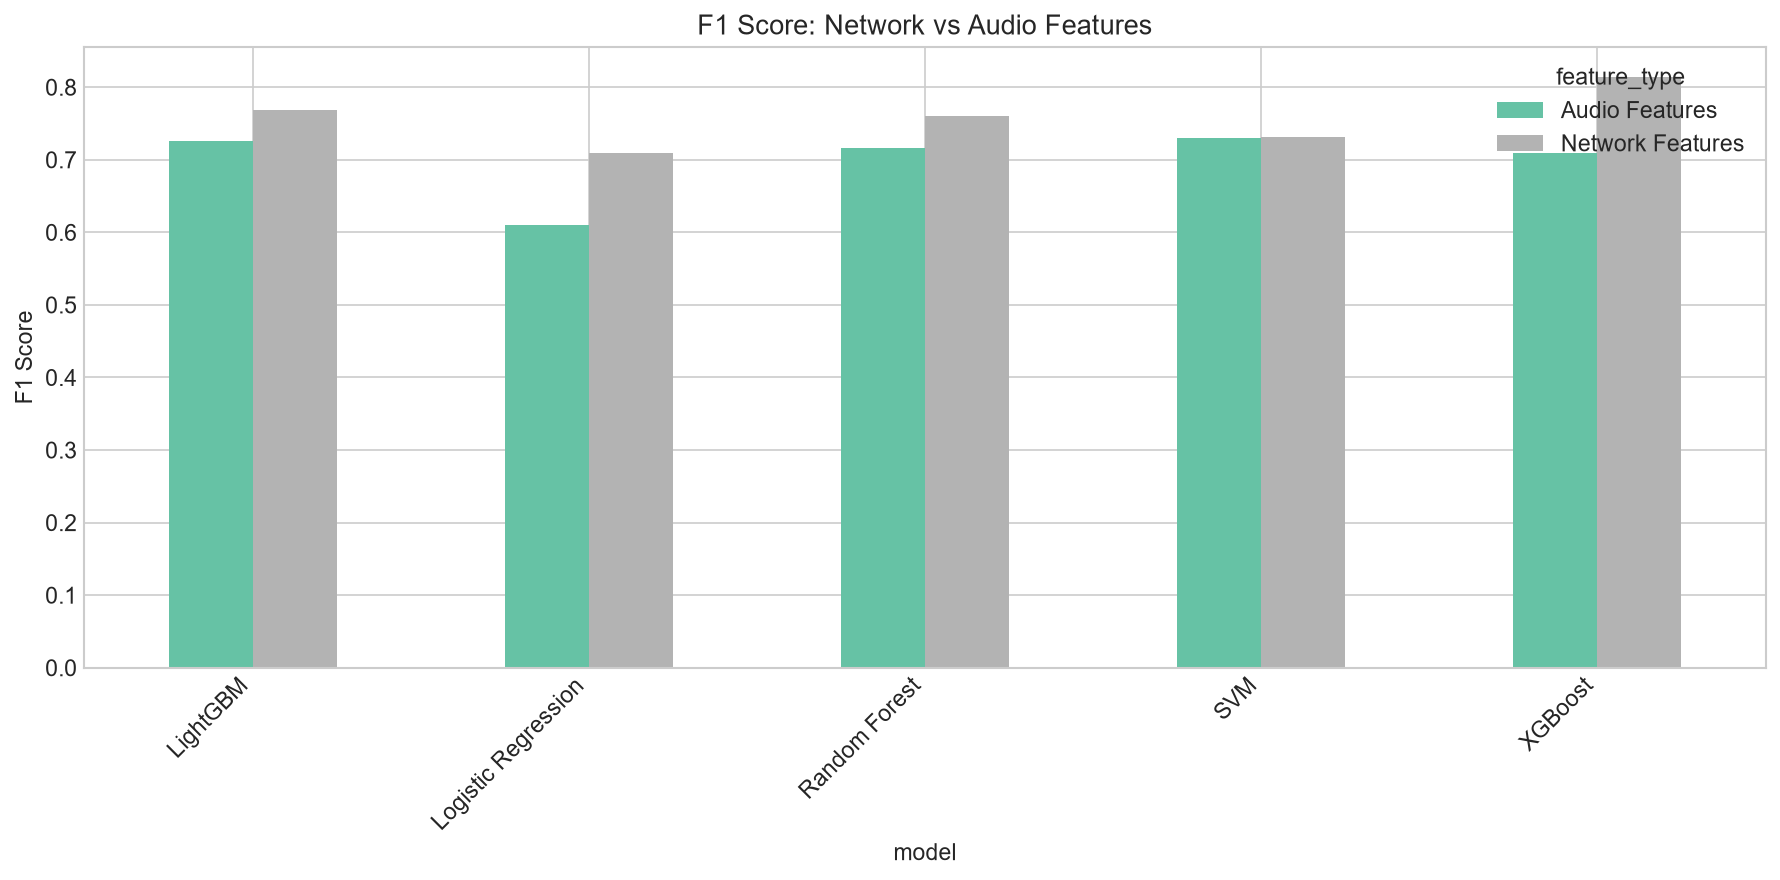

In [4]:
comparison = evaluator.compare_models(results_network, results_audio)
display(comparison)

evaluator.save_comparison_table(comparison, '../reports/baseline_comparison.csv')

# Visualization
pivot = comparison.pivot(index='model', columns='feature_type', values='f1')
pivot.plot(kind='bar', figsize=(12, 6), colormap='Set2')
plt.title('F1 Score: Network vs Audio Features')
plt.ylabel('F1 Score')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/15_baseline_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


In [5]:
# Full metrics table
metrics_df = evaluator.metrics_to_dataframe(results_network)
metrics_df.columns = [f'network_{c}' for c in metrics_df.columns]
audio_df = evaluator.metrics_to_dataframe(results_audio)
audio_df.columns = [f'audio_{c}' for c in audio_df.columns]
full_table = pd.concat([metrics_df, audio_df], axis=1)
display(full_table.round(4))


,network_accuracy,network_precision,network_recall,network_f1,network_roc_auc,network_time,audio_accuracy,audio_precision,audio_recall,audio_f1,audio_roc_auc,audio_time
Logistic Regression,0.732,0.9318,0.5734,0.7100,0.9027,0.0247,0.666,0.9190,0.4563,0.6098,0.6448,0.5990
Random Forest,0.775,0.9753,0.6224,0.7599,0.9593,0.3290,0.744,0.9788,0.5647,0.7162,0.8777,0.3890
XGBoost,0.818,0.9756,0.6993,0.8147,0.9112,0.2627,0.737,0.9612,0.5629,0.7100,0.8653,0.8058
LightGBM,0.781,0.9732,0.6346,0.7683,0.9459,2.0571,0.750,0.9708,0.5804,0.7265,0.8784,0.9488
SVM,0.753,0.9683,0.5874,0.7312,0.9098,0.1557,0.721,0.8164,0.6608,0.7304,0.7227,0.9019


**Next:** [Notebook 5 — Deep Learning](05_deep_learning.ipynb)
